In [24]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score , classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPool2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout



In [25]:
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

# Separate features (x) and labels (y) for training data
x_train = train_df.drop('label', axis=1)
y_train = train_df['label']

# Separate features (x) and labels (y) for test data
x_test = test_df.drop('label', axis=1)
y_test = test_df['label']

In [26]:
# Normalize pixel values to be between 0 and 1
x_train = x_train / 255.0
x_test = x_test / 255.0

In [27]:
x_train

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.019608,0.0,0.0,...,0.000000,0.000000,0.000000,0.117647,0.168627,0.000000,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.003922,0.007843,0.0,0.0,0.000000,0.0,0.0,...,0.011765,0.000000,0.000000,0.000000,0.000000,0.003922,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
59996,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.286275,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
59997,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.627451,0.635294,0.639216,0.529412,0.368627,0.000000,0.0,0.0,0.0,0.0
59998,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0


In [28]:
percept_model = Perceptron()

In [29]:
x_test

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.035294,0.031373,0.000000,...,0.403922,0.341176,0.219608,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
1,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.133333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
2,0.0,0.000000,0.000000,0.0,0.0,0.0,0.054902,0.207843,0.388235,0.066667,...,0.000000,0.000000,0.000000,0.000000,0.247059,0.207843,0.121569,0.000000,0.000000,0.0
3,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.631373,...,0.537255,0.494118,0.549020,0.000000,0.521569,0.878431,0.870588,0.219608,0.000000,0.0
4,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.145098,...,0.125490,0.090196,0.054902,0.078431,0.000000,0.000000,0.003922,0.000000,0.000000,0.0
9996,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.007843,0.203922,0.090196,0.109804,0.000000,0.000000,0.0
9997,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.686275,0.674510,0.674510,0.713725,0.780392,0.870588,0.164706,0.000000,0.003922,0.0
9998,0.0,0.003922,0.011765,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.003922,0.000000,0.000000,0.000000,0.0


In [30]:
percept_model.fit(x_train, y_train)

Perceptron()

In [31]:
percept_predict = percept_model.predict(x_test)

In [32]:
print(classification_report(y_test, percept_predict))

              precision    recall  f1-score   support

           0       0.65      0.87      0.74      1000
           1       0.98      0.95      0.97      1000
           2       0.90      0.35      0.51      1000
           3       0.66      0.94      0.77      1000
           4       0.80      0.50      0.61      1000
           5       0.91      0.91      0.91      1000
           6       0.44      0.57      0.50      1000
           7       0.84      0.95      0.89      1000
           8       0.96      0.91      0.93      1000
           9       0.97      0.86      0.91      1000

    accuracy                           0.78     10000
   macro avg       0.81      0.78      0.77     10000
weighted avg       0.81      0.78      0.77     10000



Artifitial neural network

In [33]:
ANN_Model = keras.Sequential([
    layers.Input(shape=(x_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [34]:
ANN_Model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [47]:
history_ann = ANN_Model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=10,
    batch_size=32
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9128 - loss: 0.2311 - val_accuracy: 0.8892 - val_loss: 0.3098
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9156 - loss: 0.2255 - val_accuracy: 0.8881 - val_loss: 0.3071
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9176 - loss: 0.2171 - val_accuracy: 0.8926 - val_loss: 0.3075
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9197 - loss: 0.2107 - val_accuracy: 0.8932 - val_loss: 0.3035
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9221 - loss: 0.2060 - val_accuracy: 0.8893 - val_loss: 0.3233
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9253 - loss: 0.1985 - val_accuracy: 0.8967 - val_loss: 0.3100
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9269 - loss: 0.1937 - val_accuracy: 0.8780 - val_loss: 0.3602
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9279 - loss: 0.1894

In [36]:
print(ANN_Model.evaluate(x_test, y_test))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8939 - loss: 0.3063
[0.30630552768707275, 0.8938999772071838]


In [37]:
CNN_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [38]:
CNN_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [39]:
history = CNN_model.fit(
    x_train.values.reshape(-1, 28, 28, 1), y_train,
    validation_data=(x_test.values.reshape(-1, 28, 28, 1), y_test),
    epochs=10,
    batch_size=32
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 69s 36ms/step - accuracy: 0.7829 - loss: 0.5966 - val_accuracy: 0.8418 - val_loss: 0.4188
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 65s 35ms/step - accuracy: 0.8539 - loss: 0.3993 - val_accuracy: 0.8698 - val_loss: 0.3511
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 63s 34ms/step - accuracy: 0.8766 - loss: 0.3373 - val_accuracy: 0.8797 - val_loss: 0.3250
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 85s 35ms/step - accuracy: 0.8903 - loss: 0.2984 - val_accuracy: 0.8875 - val_loss: 0.3020
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 65s 35ms/step - accuracy: 0.8992 - loss: 0.2722 - val_accuracy: 0.8899 - val_loss: 0.3012
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 35ms/step - accuracy: 0.9076 - loss: 0.2479 - val_accuracy: 0.9006 - val_loss: 0.2698
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9160 - loss: 0.2273 - val_accuracy: 0.8953 - val_loss: 0.2929
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 71s 38ms/step - accuracy: 0.9207 -

In [40]:
CNN_model.evaluate(x_test.values.reshape(-1, 28, 28, 1), y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9081 - loss: 0.2775


[0.27754923701286316, 0.9081000089645386]

/tmp/ipykernel_2339/1545772904.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model_names, y=accuracies, palette='viridis')


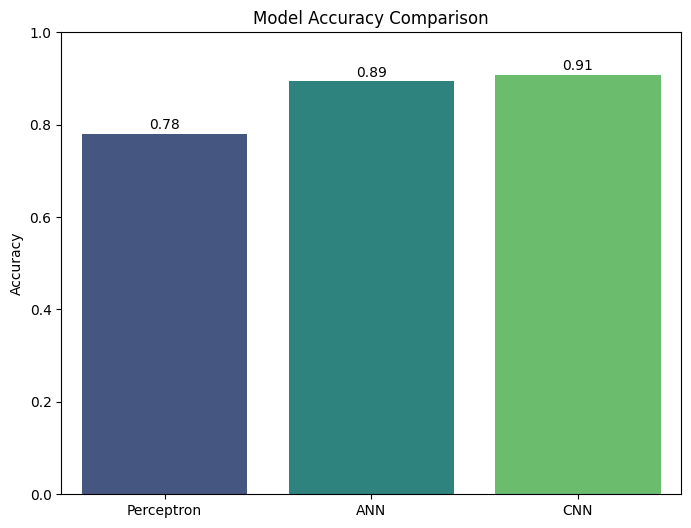

In [41]:
model_names = ['Perceptron', 'ANN', 'CNN']
perceptron_accuracy = 0.78 # From classification_report in cell EP2ThpQ4C6vt
ann_accuracy = 0.8938999772071838 # From ANN_Model.evaluate in cell _Rhq4HHcIg_p
cnn_accuracy = 0.9081000089645386 # From CNN_model.evaluate in cell 2XXHDEUnLot2

accuracies = [perceptron_accuracy, ann_accuracy, cnn_accuracy]

plt.figure(figsize=(8, 6))
sns.barplot(x=model_names, y=accuracies, palette='viridis')
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1) # Set y-axis limit from 0 to 1 for accuracy
for index, value in enumerate(accuracies):
    plt.text(index, value + 0.01, f'{value:.2f}', ha='center')
plt.show()

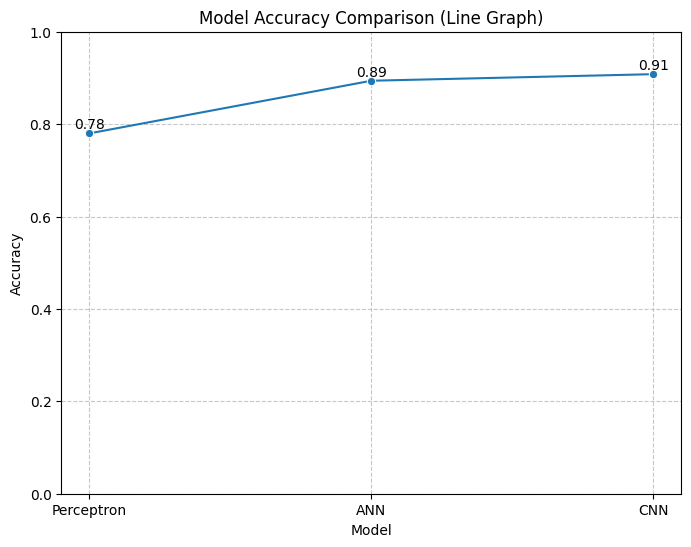

In [46]:
import pandas as pd

# Ensure plot_df is available, recalculating if necessary
model_names = ['Perceptron', 'ANN', 'CNN']
perceptron_accuracy = 0.78 # From classification_report in cell EP2ThpQ4C6vt
ann_accuracy = 0.8938999772071838 # From ANN_Model.evaluate in cell _Rhq4HHcIg_p
cnn_accuracy = 0.9081000089645386 # From CNN_model.evaluate in cell 2XXHDEUnLot2
accuracies = [perceptron_accuracy, ann_accuracy, cnn_accuracy]

plot_df = pd.DataFrame({'Model': model_names, 'Accuracy': accuracies})

plt.figure(figsize=(8, 6))
sns.lineplot(x='Model', y='Accuracy', data=plot_df, marker='o', sort=False)
plt.title('Model Accuracy Comparison (Line Graph)')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1) # Set y-axis limit from 0 to 1 for accuracy

for i, row in plot_df.iterrows():
    plt.text(row.name, row['Accuracy'] + 0.01, f'{row['Accuracy']:.2f}', ha='center')

plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


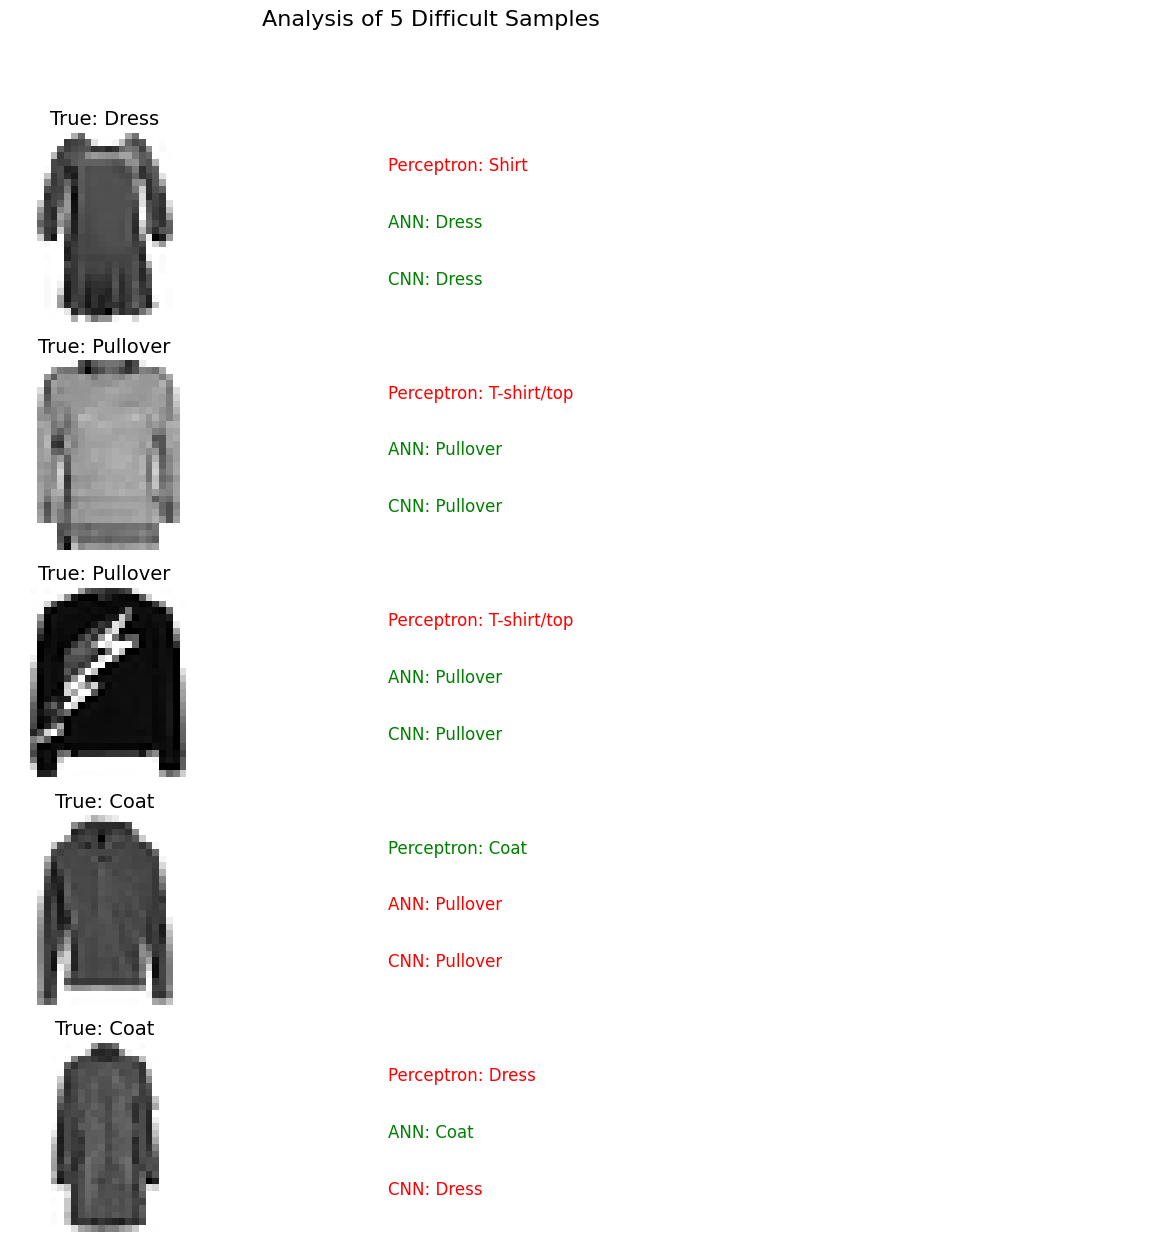

In [51]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Get full predictions for all test samples for easier comparison
# Perceptron predictions are already available in `percept_predict`

ann_full_predict_probs = ANN_Model.predict(x_test)
ann_full_predict = np.argmax(ann_full_predict_probs, axis=1)

cnn_full_predict_probs = CNN_model.predict(x_test.values.reshape(-1, 28, 28, 1))
cnn_full_predict = np.argmax(cnn_full_predict_probs, axis=1)

# Identify indices of 'difficult' samples (where at least one model misclassified)
misclassified_indices = []
for i in range(len(y_test)):
    is_misclassified_perceptron = (percept_predict[i] != y_test.iloc[i])
    is_misclassified_ann = (ann_full_predict[i] != y_test.iloc[i])
    is_misclassified_cnn = (cnn_full_predict[i] != y_test.iloc[i])

    if is_misclassified_perceptron or is_misclassified_ann or is_misclassified_cnn:
        misclassified_indices.append(i)

# Select a few random examples from these difficult samples
num_examples_to_show = 5

if len(misclassified_indices) > num_examples_to_show:
    # Ensure we don't try to pick more samples than available
    selected_difficult_indices = np.random.choice(misclassified_indices, num_examples_to_show, replace=False)
else:
    selected_difficult_indices = misclassified_indices # Use all if less than requested

plt.figure(figsize=(15, num_examples_to_show * 2.5))

for i, idx in enumerate(selected_difficult_indices):
    # Get the image and true label
    image = x_test.loc[idx].values.reshape(28, 28)
    true_label = y_test.loc[idx]

    # Get predictions for this specific index
    perceptron_pred = percept_predict[idx]
    ann_pred = ann_full_predict[idx]
    cnn_pred = cnn_full_predict[idx]

    # Plotting
    plt.subplot(num_examples_to_show, 2, 2*i + 1) # Image plot
    plt.imshow(image, cmap=plt.cm.binary)
    plt.title(f"True: {class_names[true_label]}", fontsize=14)
    plt.axis('off')

    plt.subplot(num_examples_to_show, 2, 2*i + 2) # Predictions text
    plt.text(0.05, 0.8, f"Perceptron: {class_names[perceptron_pred]}", fontsize=12,
             color='green' if perceptron_pred == true_label else 'red')
    plt.text(0.05, 0.5, f"ANN: {class_names[ann_pred]}", fontsize=12,
             color='green' if ann_pred == true_label else 'red')
    plt.text(0.05, 0.2, f"CNN: {class_names[cnn_pred]}", fontsize=12,
             color='green' if cnn_pred == true_label else 'red')
    plt.axis('off')

plt.suptitle(f'Analysis of {num_examples_to_show} Difficult Samples', fontsize=16, y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Adjust layout to prevent title overlap
plt.show()